Exercise C.1 (UML fact checker)  

| # | Statement | Answer | Reason |
|---|-----------|--------|--------|
| 1 | No two universities can have the same name | **No** | Nothing in the diagram restricts the values of `name`. |
| 2 | A university and a student can not have the same name | **No** | The attributes are independent, equal values are allowed. |
| 3 | No student studies at more than one university | **Yes** | In a composition a part belongs to at most one whole. |
| 4 | Each student studies at at least one university | **Yes** | A part of a composition cannot exist without its whole. |
| 5 | Two students with the same name can not study at the same university | **No** | `name` is not marked as unique. |
| 6 | Two students with the same name can not study at different universities | **No** | Same reason as 5. |
| 7 | Two universities can have the same address | **Yes** | Nothing forbids equal `Address` values. |

Exercise C.2 (From text to UML) Convert the following description into an appropriate UML diagram, with multiplicities and associations.

    Every person has a name, a phone number and an e-mail address.
    Every address is only occupied by one person, some addresses might have no inhabitant.
    Each address is associated with a street, a city, an area code, and a country.
    Addresses can be verified as a home address for a person and printed for post service.
    There are two types of persons:
        Students that can enlist for a class
        Professors that can receive a salary
    A student has a study ID and an average grade.


```mermaid
classDiagram
    class Person {
        <<abstract>>
        - name: string
        - phoneNumber: string
        - email: string
    }

    class Address {
        - street: string
        - city: string
        - areaCode: string
        - country: string
        + validate(person: Person) bool
        + outputAsLabel() string
    }

    class Student {
        - studyId: int
        - averageGrade: float
        + enlist(course: string) bool
    }

    class Professor {
        - salary: float
        + receiveSalary(amount: float)
    }

    Person "0..1" -- "1" Address : lives at
    Person <|-- Student
    Person <|-- Professor
```

- `Person` is abstract, since every person is either a student or a professor.
- **Association** `lives at`: an address has at most one inhabitant (`0..1`),
  every person has one address (`1`, assumption).
- **Generalization**: `Student` and `Professor` inherit all attributes of `Person`.
- The abilities from the text become methods: verifying (`validate`),
  printing for post service (`outputAsLabel`), enlisting (`enlist`)
  and receiving a salary (`receiveSalary`).
- Attributes are private (`-`), methods public (`+`).

Exercise C.3 (From UML to Python) Convert the UML diagram from Exercise C.2 into Python code and test your classes.

In [3]:
from abc import ABC


class Address:
    def __init__(self, street: str, city: str, area_code: str, country: str):
        self._street = street
        self._city = city
        self._area_code = area_code
        self._country = country
        self._inhabitant: "Person | None" = None   # 0..1

    def validate(self, person: "Person") -> bool:
        """Check if this address is the home address of the given person."""
        return self._inhabitant is person

    def output_as_label(self) -> str:
        name = self._inhabitant.name if self._inhabitant else "Current Resident"
        return f"{name}\n{self._street}\n{self._area_code} {self._city}\n{self._country.upper()}"


class Person(ABC):
    def __init__(self, name: str, phone_number: str, email: str, address: Address):
        if address._inhabitant is not None:
            raise ValueError("Address is already occupied")
        self._name = name
        self._phone_number = phone_number
        self._email = email
        self._address = address          # 1
        address._inhabitant = self

    @property
    def name(self) -> str:
        return self._name


class Student(Person):
    def __init__(self, name, phone_number, email, address,
                 study_id: int, average_grade: float):
        super().__init__(name, phone_number, email, address)
        self._study_id = study_id
        self._average_grade = average_grade
        self._courses: list[str] = []

    def enlist(self, course: str) -> bool:
        if course in self._courses:
            return False
        self._courses.append(course)
        return True


class Professor(Person):
    def __init__(self, name, phone_number, email, address, salary: float):
        super().__init__(name, phone_number, email, address)
        self._salary = salary
        self._balance = 0.0

    def receive_salary(self, amount: float | None = None) -> None:
        self._balance += self._salary if amount is None else amount


# ---------------- Tests ----------------
if __name__ == "__main__":
    a1 = Address("Universitätsstraße 15", "Innsbruck", "6020", "Austria")
    a2 = Address("Technikerstraße 13", "Innsbruck", "6020", "Austria")
    a3 = Address("Maria-Theresien-Straße 1", "Innsbruck", "6020", "Austria")

    s = Student("Anna", "+43 660 1234567", "anna@mci.edu", a1, 12345, 1.8)
    p = Professor("Dr. Berger", "+43 512 2070", "berger@mci.edu", a2, 5000.0)

    # Person is abstract (in the UML sense): only students / professors are used
    assert isinstance(s, Person) and isinstance(p, Person)

    # validate
    assert a1.validate(s) is True
    assert a1.validate(p) is False

    # address occupied by at most one person
    try:
        Student("Ben", "000", "ben@mci.edu", a1, 2, 2.0)
        raise AssertionError("should not be possible")
    except ValueError:
        pass

    # address without inhabitant
    print(a3.output_as_label(), end="\n\n")
    print(a1.output_as_label(), end="\n\n")

    # enlist
    assert s.enlist("Softwaredesign") is True
    assert s.enlist("Softwaredesign") is False

    # salary
    p.receive_salary()
    p.receive_salary(200.0)
    assert p._balance == 5200.0

    print("All tests passed.")

Current Resident
Maria-Theresien-Straße 1
6020 Innsbruck
AUSTRIA

Anna
Universitätsstraße 15
6020 Innsbruck
AUSTRIA

All tests passed.


Exercise C.4 (Interface) Consider the following UML diagram and implement it in Python with interfaces. Set lives for a Cat to the appropriate 7, feed some cat food generated with random integers uniformly distributed between and and look how much food it can eat until it dies. Plot this for different initial values of currentFood.

The cat runs to the kitchen.
The cat breathes.
Lives: 7 | Food: 20
initial food =   1  ->  median meals until death = 77
initial food =   5  ->  median meals until death = 167
initial food =  10  ->  median meals until death = 550
initial food =  20  ->  median meals until death = 1601
initial food =  30  ->  median meals until death = 2976
initial food =  40  ->  median meals until death = 5672
initial food =  50  ->  median meals until death = 9569


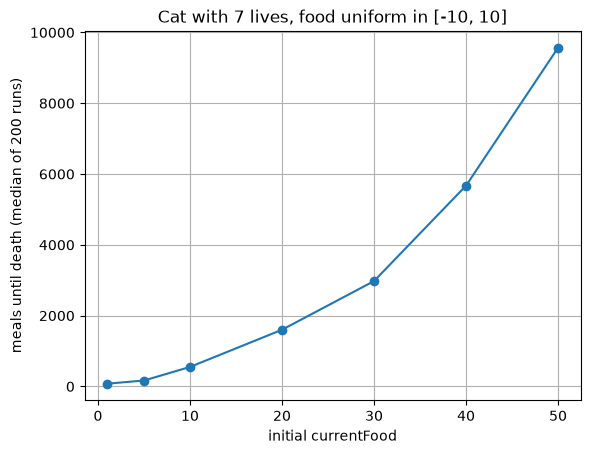

In [4]:
import random
from abc import ABC, abstractmethod

import matplotlib.pyplot as plt


# ---------------- Interfaces ----------------
class FourLegged(ABC):
    @abstractmethod
    def run(self, destination: str) -> None: ...


class OxygenBreather(ABC):
    @abstractmethod
    def breath(self) -> None: ...


# ---------------- Base class ----------------
class Animal:
    def __init__(self, lives: int, current_food: int):
        self._lives = lives
        self._current_food = current_food

    def eat(self, food: int) -> None:
        self._current_food += food


# ---------------- Cat ----------------
class Cat(Animal, FourLegged, OxygenBreather):
    def __init__(self, current_food: int):
        super().__init__(lives=7, current_food=current_food)
        self._start_food = current_food

    def eat(self, food: int) -> None:
        """Eat food; if the food level drops to 0 or below, the cat loses a life
        and starts again with its initial amount of food."""
        if self._lives <= 0:
            return
        super().eat(food)
        if self._current_food <= 0:
            self.__decrease_lives()
            self._current_food = self._start_food

    def get_lives_left(self) -> int:
        return self._lives

    def get_current_amount_of_food(self) -> int:
        return self._current_food

    def __decrease_lives(self) -> None:          # private (UML "-")
        self._lives -= 1

    def run(self, destination: str) -> None:
        print(f"The cat runs to {destination}.")

    def breath(self) -> None:
        print("The cat breathes.")


# ---------------- Simulation ----------------
def meals_until_death(initial_food: int, max_meals: int = 1_000_000) -> int:
    """Feed the cat random food in [-10, 10] until all 7 lives are gone."""
    cat = Cat(initial_food)
    meals = 0
    while cat.get_lives_left() > 0 and meals < max_meals:
        cat.eat(random.randint(-10, 10))
        meals += 1
    return meals


if __name__ == "__main__":
    random.seed(42)

    cat = Cat(20)
    cat.run("the kitchen")
    cat.breath()
    print("Lives:", cat.get_lives_left(), "| Food:", cat.get_current_amount_of_food())

    initial_values = [1, 5, 10, 20, 30, 40, 50]
    runs = 200
    median_meals = []
    for food in initial_values:
        results = sorted(meals_until_death(food) for _ in range(runs))
        median_meals.append(results[runs // 2])   # median: robust against rare very long runs
        print(f"initial food = {food:>3}  ->  median meals until death = {median_meals[-1]}")

    plt.plot(initial_values, median_meals, marker="o")
    plt.xlabel("initial currentFood")
    plt.ylabel(f"meals until death (median of {runs} runs)")
    plt.title("Cat with 7 lives, food uniform in [-10, 10]")
    plt.grid(True)
    plt.savefig("c4_cat_plot.png", dpi=120, bbox_inches="tight")
    plt.show()

Exercise C.5 (Iterators) Explain the output of the following code fragment, see Section 6.1:

An iterator can only be traversed **once**. To use the values
multiple times, either create a new iterator or store them,
e.g. `values = list(map(square, range(1, 5)))`.

Exercise C.6 (Accumulator) In Section 6.1 we discussed the functools module. On function included there is accumulate that takes an iterator and a function to apply to it. It can, for example be used to compute partial sum or product:

In [ ]:
from itertools import accumulate, repeat

numbers = [3, 1, 4, 1, 5, 9, 2, 6]
print(f"{list(accumulate(numbers, max)) = }")

loan = 1000       
interest = 0.05    
payment = 100      
years = 10

balances = accumulate(
    repeat(payment, years),
    lambda balance, pmt: balance * (1 + interest) - pmt,
    initial=loan,
)

print("Year   Balance")
for year, balance in enumerate(balances):
    print(f"{year:>4}  {balance:>9.2f}")

list(accumulate(numbers, max)) = [3, 3, 4, 4, 5, 9, 9, 9]
Year   Balance
   0    1000.00
   1     950.00
   2     897.50
   3     842.38
   4     784.49
   5     723.72
   6     659.90
   7     592.90
   8     522.54
   9     448.67
  10     371.11


Exercise C.7 (Filter) Use functional programming and in particular the filter function to:

    Find all palindromes in a list of strings.

    Count the number of vowels in a string.


In [ ]:
# 1. Palindromes
words = ["Anna", "Python", "Otto", "level", "Rentner", "Hallo", "Lagerregal"]

is_palindrome = lambda s: s.lower() == s.lower()[::-1]
palindromes = list(filter(is_palindrome, words))
print(f"{palindromes = }")

# 2. Count vowels
text = "Functional programming is fun"

vowels = list(filter(lambda c: c in "aeiou", text.lower()))
print(f"{len(vowels) = }")

Exercise C.8 (Creating a module) Create your own module. The module should have the following functions:

    For a given year, check if it is a leap year.
    For a given date, return the day of the week, use the algorithm outlined here. Hint: Dictionaries can help you for some of the mappings.
    Return the week number of the year of a certain date, you can use the algorithm outlined here.
    Provide doc strings for each of your methods and for the module itself.


In [7]:
"""mydates - small calendar helper module.

Provides functions to
* check whether a year is a leap year,
* compute the day of the week of a date (key value method, almanac.com),
* compute the ISO week number of a date.

Only the Gregorian calendar is supported.

Example:
    >>> import mydates
    >>> mydates.is_leap_year(2024)
    True
    >>> mydates.day_of_week(2, 11, 2026)
    'Monday'
    >>> mydates.week_number(2, 11, 2026)
    45
"""

# key values of the months for the day-of-week algorithm
MONTH_KEYS = {1: 1, 2: 4, 3: 4, 4: 0, 5: 2, 6: 5,
              7: 0, 8: 3, 9: 6, 10: 1, 11: 4, 12: 6}

# century codes repeat every 400 years: 1700s -> 4, 1800s -> 2, 1900s -> 0, 2000s -> 6
CENTURY_CODES = {0: 6, 1: 4, 2: 2, 3: 0}

# remainder of the algorithm -> name of the weekday
WEEKDAYS = {0: "Saturday", 1: "Sunday", 2: "Monday", 3: "Tuesday",
            4: "Wednesday", 5: "Thursday", 6: "Friday"}

DAYS_IN_MONTH = {1: 31, 2: 28, 3: 31, 4: 30, 5: 31, 6: 30,
                 7: 31, 8: 31, 9: 30, 10: 31, 11: 30, 12: 31}


def is_leap_year(year: int) -> bool:
    """Return True if `year` is a leap year.

    A year is a leap year if it is divisible by 4, except for years
    divisible by 100 that are not divisible by 400.
    """
    return year % 4 == 0 and (year % 100 != 0 or year % 400 == 0)


def day_of_week(day: int, month: int, year: int) -> str:
    """Return the name of the weekday of the given date (key value method).

    Steps:
    1. take the last two digits of the year and divide them by 4 (integer division)
    2. add the day of the month
    3. add the key value of the month
    4. subtract 1 for January or February of a leap year
    5. add the century code
    6. add the last two digits of the year
    7. the remainder of the division by 7 gives the weekday
    """
    yy = year % 100
    total = yy // 4 + day + MONTH_KEYS[month]
    if month in (1, 2) and is_leap_year(year):
        total -= 1
    total += CENTURY_CODES[(year // 100) % 4] + yy
    return WEEKDAYS[total % 7]


def day_of_year(day: int, month: int, year: int) -> int:
    """Return the ordinal day of the year (1 = January 1st)."""
    days = sum(DAYS_IN_MONTH[m] for m in range(1, month)) + day
    if month > 2 and is_leap_year(year):
        days += 1
    return days


def _iso_weekday(day: int, month: int, year: int) -> int:
    """Return the ISO weekday number (Monday = 1, ..., Sunday = 7)."""
    names = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]
    return names.index(day_of_week(day, month, year)) + 1


def _weeks_in_year(year: int) -> int:
    """Return the number of ISO weeks (52 or 53) of a year."""
    # a year has 53 weeks if it starts on Thursday,
    # or if it is a leap year starting on Wednesday
    jan1 = _iso_weekday(1, 1, year)
    return 53 if jan1 == 4 or (jan1 == 3 and is_leap_year(year)) else 52


def week_number(day: int, month: int, year: int) -> int:
    """Return the ISO 8601 week number of the given date.

    Weeks start on Monday, and week 1 is the week containing the first
    Thursday of the year. Formula: (day_of_year - weekday + 10) // 7.
    Dates at the start of January can belong to the last week of the
    previous year, dates at the end of December to week 1 of the next year.
    """
    week = (day_of_year(day, month, year) - _iso_weekday(day, month, year) + 10) // 7
    if week < 1:
        return _weeks_in_year(year - 1)
    if week > _weeks_in_year(year):
        return 1
    return week

Exercise C.9 (Using your own module) Use the module created in Exercise C.8 and build a program on it.

Exercise C.8 (Creating a module) Create your own module. The module should have the following functions:

    For a given year, check if it is a leap year.
    For a given date, return the day of the week, use the algorithm outlined here. Hint: Dictionaries can help you for some of the mappings.
    Return the week number of the year of a certain date, you can use the algorithm outlined here.
    Provide doc strings for each of your methods and for the module itself.

    Include the local module via pdm.
    Use the module to generate from a date the following output
        leap year -> true/false
        day of the week
        week of the year
    How can you deal with european and american styled day-month order?
    Update your module by adding the above described function where the returned value should be a dictionary with keys: leapyear, weekday,week.
    Can you use the new function in the module right away or do you need to reinstall it somehow?


In [1]:
import importlib
import mydates

importlib.reload(mydates)   # load the latest version of the module

dates = [("02.11.2026", "eu"),
         ("11/02/2026", "us"),
         ("29.02.2024", "eu"),
         ("2027-01-01", "eu")]

for date, style in dates:
    info = mydates.date_info(date, style)
    print(f"{date} ({style})")
    print(f"  leap year -> {str(info['leapyear']).lower()}")
    print(f"  day of the week: {info['weekday']}")
    print(f"  week of the year: {info['week']}")

# same day in european and american notation
assert mydates.date_info("02.11.2026", "eu") == mydates.date_info("11/02/2026", "us")
print(mydates.date_info("02.11.2026"))

02.11.2026 (eu)
  leap year -> false
  day of the week: Monday
  week of the year: 45
11/02/2026 (us)
  leap year -> false
  day of the week: Monday
  week of the year: 45
29.02.2024 (eu)
  leap year -> true
  day of the week: Thursday
  week of the year: 9
2027-01-01 (eu)
  leap year -> false
  day of the week: Friday
  week of the year: 53
{'leapyear': False, 'weekday': 'Monday', 'week': 45}
